# Notebook 03: Pipeline consolidado, comparación y decisión final

**Responsable:** Persona 3 (Paquete C)
**Integra:** Paquete A (K-Means, `01_kmeans.ipynb`) y Paquete B (DBSCAN, `02_dbscan.ipynb`)
**Cómo ejecutarlo:** *Kernel → Restart & Run All*. Corre de principio a fin sin intervención y se detiene con un error si algún artefacto de los Paquetes A o B no coincide con lo que aquí se reproduce.

Este notebook **no exporta modelos nuevos**. Reproduce los dos modelos con la misma semilla (`RANDOM_STATE = 42`), comprueba que coinciden con los artefactos guardados, los compara con los criterios del documento maestro, elige el modelo final y genera `tables/comparacion.csv` y `figs/comparacion.png`.

**Índice:** 1. Contexto · 2. Preparación · 3. EDA y PCA · 4. K-Means · 5. DBSCAN · 6. Comparación y decisión · 7. Segmentos · 8. Exportación e inferencia · 9. Resumen para la sustentación

## 1. Contexto y pregunta de negocio

**Propósito y fundamento:** este es un problema de **aprendizaje no supervisado**: no existe una columna que diga a qué grupo pertenece cada estudiante. Con 16 variables académicas, de hábitos y socioemocionales, el algoritmo agrupa a los estudiantes que se parecen entre sí según la distancia euclidiana en el espacio escalado. El objetivo es institucional: asignar a cada grupo una acción concreta (apoyo económico, tutoría, seguimiento de bienestar o reconocimiento) para prevenir la deserción y atender el burnout.

`Burnout_Level` y `Dropout_Risk` son **etiquetas de clase** y quedan fuera de todo el flujo: no se usan para imputar, escalar, proyectar ni agrupar. Si se usaran, el problema dejaría de ser clustering y pasaría a ser clasificación disfrazada.

In [1]:
# Librerías del flujo completo: datos, modelos, métricas y figuras.
import json
import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

# Las rutas del contrato son relativas a la raíz del proyecto; funciona tanto si
# el notebook se abre desde notebooks/ como desde la raíz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

DATA_PATH = Path("data/student_burnout_dropout_dataset_2_link 1.csv")
FEATURES = json.loads(Path("data/feature_names.json").read_text(encoding="utf-8"))

# Salvaguarda del contrato: las etiquetas de clase nunca pueden entrar en la matriz X.
assert len(FEATURES) == 16
assert "Burnout_Level" not in FEATURES and "Dropout_Risk" not in FEATURES
print("Raíz del proyecto:", ROOT)
print("Variables del modelo (orden del contrato):", FEATURES)

Raíz del proyecto: /home/claude/alex171215/proyecto-dbscan-kmeans-rda2
Variables del modelo (orden del contrato): ['Age', 'Year_of_Study', 'Attendance_Percent', 'Study_Hours_Per_Day', 'Previous_GPA', 'Backlogs', 'Sleep_Hours', 'Screen_Time_Hours', 'Exercise_Freq_Per_Week', 'Social_Activity_Score', 'Financial_Stress_Score', 'Family_Support_Score', 'Stress_Level', 'Anxiety_Score', 'Motivation_Score', 'Peer_Pressure_Score']


## 2. Preparación de datos: imputación y escalado

**Propósito y fundamento:** K-Means y DBSCAN deciden por **distancias**. Si una variable tiene una escala mayor (por ejemplo `Attendance_Percent`, de 0 a 100, frente a `Backlogs`, de 0 a pocas unidades), dominaría la distancia sólo por sus unidades. Por eso:
- `SimpleImputer(strategy="median")` rellena los faltantes con la mediana, que no se mueve con los valores extremos.
- `StandardScaler()` transforma cada variable a media 0 y desviación 1: $z = (x - \mu)/\sigma$.

Ambos pasos se ajustan sobre los mismos 800 registros para los dos modelos, así compiten en igualdad de condiciones.

In [2]:
df = pd.read_csv(DATA_PATH)
# Sólo las 16 variables del contrato; Student_ID, categóricas y etiquetas quedan fuera.
X_raw = df[FEATURES].copy()

faltantes = X_raw.isna().sum()
print(f"Registros: {X_raw.shape[0]} | Variables: {X_raw.shape[1]}")
print(f"Celdas faltantes: {int(faltantes.sum())} en {int((faltantes > 0).sum())} variables")
print(faltantes[faltantes > 0].sort_values(ascending=False).to_string())

Registros: 800 | Variables: 16
Celdas faltantes: 504 en 13 variables
Attendance_Percent        51
Stress_Level              49
Family_Support_Score      44
Financial_Stress_Score    43
Motivation_Score          41
Peer_Pressure_Score       41
Social_Activity_Score     40
Anxiety_Score             39
Screen_Time_Hours         36
Previous_GPA              35
Sleep_Hours               35
Study_Hours_Per_Day       35
Backlogs                  15


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa para el negocio?* Hay 504 celdas faltantes repartidas en 13 de las 16 variables; la que más tiene es `Attendance_Percent` (51). No se elimina ninguna fila: perder a los estudiantes con registros incompletos sesgaría los perfiles justo hacia quienes completan todo.
2. *¿Qué decisión técnica se toma?* Imputar con la mediana y escalar con `StandardScaler`, dentro de un `Pipeline`, para que un registro nuevo en la app reciba exactamente la misma transformación.
3. *¿Cómo defenderlo? — "¿Por qué StandardScaler y no MinMaxScaler?"* MinMaxScaler depende sólo del mínimo y el máximo, que suelen ser valores extremos; uno solo de ellos comprime al resto de estudiantes en un rango pequeño. StandardScaler usa media y desviación, que resumen a todo el grupo, y deja cada variable con el mismo peso en la distancia.

## 3. Análisis exploratorio resumido y PCA

**Propósito y fundamento:** la correlación de Pearson ($r$) mide asociación lineal entre dos variables; si $|r|$ es alto, ambas aportan casi la misma información. El **PCA** reorganiza las 16 dimensiones en componentes ortogonales ordenadas por varianza explicada. Los **loadings** (pesos de cada variable en una componente) indican qué significa cada eje. Se usa el PCA base de `00_foundation.py` (`models/pca.joblib`) sólo para entender la estructura y dibujar el mapa 2D; **ningún modelo se entrena sobre el PCA**. El EDA completo (outliers por Tukey, distribuciones, boxplots) está en los notebooks 01 y 02; aquí se resume lo que sustenta la decisión final.

In [3]:
# Correlación entre pares de variables originales (sin la diagonal, que siempre vale 1).
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print(f"Correlación absoluta máxima entre dos variables: {corr.max():.2f}")
print(f"Pares con |r| >= 0.50: {int((corr >= 0.50).sum() // 2)}")

# Varianza explicada guardada por la base fundacional.
pca_var = pd.read_csv("data/pca_varianza.csv")
n_80 = int((pca_var["cumulative"] < 0.80).sum() + 1)
print(f"\nVarianza de PC1: {pca_var.loc[0, 'explained_variance']:.2%} | PC2: {pca_var.loc[1, 'explained_variance']:.2%}")
print(f"Varianza acumulada PC1+PC2: {pca_var.loc[1, 'cumulative']:.2%}")
print(f"Componentes necesarias para llegar al 80 %: {n_80} de {len(pca_var)}")

# Loadings: peso de cada variable original en PC1 y PC2.
pca = joblib.load("models/pca.joblib")
loadings = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
print("\nLoadings de PC1 y PC2 (ordenados por PC1):")
display(loadings.sort_values("PC1", ascending=False).round(3))

Correlación absoluta máxima entre dos variables: 0.09
Pares con |r| >= 0.50: 0

Varianza de PC1: 7.62% | PC2: 7.41%
Varianza acumulada PC1+PC2: 15.04%
Componentes necesarias para llegar al 80 %: 13 de 16

Loadings de PC1 y PC2 (ordenados por PC1):


,PC1,PC2
Family_Support_Score,0.482,-0.007
Previous_GPA,0.385,-0.279
Peer_Pressure_Score,0.340,0.175
Motivation_Score,0.304,0.149
Attendance_Percent,0.230,0.357
Social_Activity_Score,0.123,0.243
Stress_Level,0.056,-0.113
Financial_Stress_Score,0.003,-0.287
Age,-0.023,0.351
Study_Hours_Per_Day,-0.049,0.275


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa para el negocio?* La correlación máxima entre dos variables es 0.09 y ningún par llega a $|r| \geq 0.50$: cada variable aporta información propia y ninguna sobra. También anticipa un reto: los estudiantes no se separan por una o dos variables dominantes.
2. *PCA:* PC1 explica 7.6 % y PC2 7.4 %; juntas, sólo 15.0 %, y hacen falta 13 componentes para llegar al 80 %. Por eso el mapa 2D es una **ventana parcial** para visualizar, no la base de la decisión; los modelos trabajan en 16D.
   - **PC1 ≈ apoyo y rendimiento frente a hábitos de riesgo:** pesos positivos en `Family_Support_Score` (0.48), `Previous_GPA` (0.39) y `Peer_Pressure_Score` (0.34); negativos en `Screen_Time_Hours` (−0.41) y `Sleep_Hours` (−0.34).
   - **PC2 ≈ actividad y asistencia frente a presión económica:** positivos en `Exercise_Freq_Per_Week` (0.56) y `Attendance_Percent` (0.36); negativos en `Financial_Stress_Score` (−0.29) y `Previous_GPA` (−0.28).
3. *¿Cómo defenderlo? — "¿Qué representan PC1 y PC2?"* Son combinaciones lineales de las 16 variables, no variables reales; se leen por sus loadings. Como explican poco (15 %), dos estudiantes que se ven juntos en el mapa pueden estar lejos en 16D, y eso explica por qué los colores se solapan en el gráfico.

## 4. K-Means final (K = 4): reproducción y verificación

**Propósito y fundamento:** K-Means busca $K$ centroides que minimizan la **inercia**, la suma de distancias al cuadrado de cada estudiante a su centroide: $\sum_i \lVert x_i - \mu_{c(i)} \rVert^2$. El `Pipeline` encadena imputación, escalado y K-Means, de modo que la app sólo llama a `predict` con datos crudos. `n_init=10` prueba 10 arranques y conserva el de menor inercia; `random_state=42` lo hace reproducible.

$K=4$ se eligió en el Paquete A: el codo aproximado está en $K=4$ (la reducción de inercia baja de 3.50 % a 2.73 % al pasar a $K=5$) y el Silhouette es bajo para todos los $K$ entre 2 y 9 (0.0457–0.0501). Aquí sólo se reproduce y se verifica contra los artefactos guardados.

In [4]:
km_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)),
])
km_labels = km_pipe.fit_predict(X_raw)

# Matriz escalada 16D: los pasos previos al modelo (imputer + scaler).
X_scaled = km_pipe[:-1].transform(X_raw)
km_sil = silhouette_score(X_scaled, km_labels)
km_inertia = km_pipe.named_steps["kmeans"].inertia_

# Verificación contra el Paquete A: mismas etiquetas, fila por fila.
guardadas_km = pd.read_csv("segments/labels_kmeans.csv")["cluster"].to_numpy()
assert np.array_equal(km_labels, guardadas_km), "No coincide con segments/labels_kmeans.csv"

print(f"K-Means K=4 | Silhouette = {km_sil:.4f} | Inercia = {km_inertia:,.2f}")
print("Estudiantes por cluster:", dict(enumerate(np.bincount(km_labels).tolist())))
print("Etiquetas idénticas a segments/labels_kmeans.csv: sí")

K-Means K=4 | Silhouette = 0.0475 | Inercia = 11,290.70
Estudiantes por cluster: {0: 171, 1: 220, 2: 206, 3: 203}
Etiquetas idénticas a segments/labels_kmeans.csv: sí


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa para el negocio?* Los cuatro grupos tienen 171, 220, 206 y 203 estudiantes: ninguno es marginal, así que cada uno puede recibir una acción institucional propia.
2. *¿Qué decisión técnica se toma?* Se confirma el modelo del Paquete A sin cambios. El Silhouette de 0.047 es cercano a 0: muchos estudiantes están en la frontera entre dos grupos. Es una limitación del dataset (variables casi no correlacionadas, sin estructura natural fuerte) y se declara en el informe; no se "arregla" cambiando $K$ después de ver el resultado.
3. *¿Cómo defenderlo? — "¿Por qué K=4 si K=9 tiene mejor Silhouette?"* K=9 sólo mejora 0.0026 (0.0501 frente a 0.0475), está en el borde del rango probado y produciría nueve perfiles difíciles de atender. K=4 está en el codo de la inercia y da perfiles manejables.

## 5. DBSCAN final (ε = 3.2, MinPts = 32): reproducción y verificación

**Propósito y fundamento:** DBSCAN agrupa por **densidad**. Un estudiante es *core* si tiene al menos MinPts vecinos a distancia ≤ ε; los clusters crecen conectando puntos core. Quien no alcanza esa densidad ni está cerca de un core queda como **ruido (−1)**. MinPts = 32 cumple la regla MinPts ≥ 2D (2 × 16), y ε = 3.2 sale del gráfico k-dist y del barrido del Paquete B. El Silhouette se calcula **excluyendo el ruido**, como exige el contrato.

In [5]:
EPS, MIN_SAMPLES = 3.2, 32
db_labels = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X_scaled)

guardadas_db = pd.read_csv("segments/labels_dbscan.csv")["cluster"].to_numpy()
assert np.array_equal(db_labels, guardadas_db), "No coincide con segments/labels_dbscan.csv"

ruido = db_labels == -1
noise_frac = ruido.mean()
n_clusters_db = len(set(db_labels)) - (1 if ruido.any() else 0)
db_sil = silhouette_score(X_scaled[~ruido], db_labels[~ruido])

print(f"DBSCAN eps={EPS}, MinPts={MIN_SAMPLES} | clusters = {n_clusters_db}")
print(f"Ruido: {int(ruido.sum())} de {len(db_labels)} estudiantes ({noise_frac:.1%})")
print(f"Silhouette sin ruido (sobre {int((~ruido).sum())} estudiantes) = {db_sil:.4f}")
print("Tamaño por etiqueta:", pd.Series(db_labels).value_counts().sort_index().to_dict())
print("Etiquetas idénticas a segments/labels_dbscan.csv: sí")

DBSCAN eps=3.2, MinPts=32 | clusters = 2
Ruido: 704 de 800 estudiantes (88.0%)
Silhouette sin ruido (sobre 96 estudiantes) = 0.1338
Tamaño por etiqueta: {-1: 704, 0: 65, 1: 31}
Etiquetas idénticas a segments/labels_dbscan.csv: sí


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa para el negocio?* DBSCAN sólo encuentra 2 grupos densos (65 y 31 estudiantes). **704 estudiantes (88 %) quedan como ruido**: no encajan en ningún perfil y, en la práctica, requerirían revisión manual uno por uno.
2. *¿Qué decisión técnica se toma?* El Silhouette de 0.134 parece mejor que el de K-Means, pero se calcula sólo sobre los 96 estudiantes que no son ruido (12 %). No es una comparación justa con K-Means, que se mide sobre los 800.
3. *¿Cómo defenderlo? — "¿Por qué DBSCAN marcó tantos puntos como ruido?"* En 16 dimensiones las distancias entre estudiantes tienden a parecerse (maldición de la dimensionalidad): casi nadie tiene 32 vecinos dentro de ε = 3.2. Subir ε reduce el ruido, pero según el barrido del Paquete B termina fusionando a todos en un único grupo, que no sirve para segmentar.

## 6. Comparación de modelos y regla de decisión

**Propósito y fundamento:** el modelo final se elige con tres criterios del documento maestro:
1. **Silhouette** — cohesión y separación de los grupos (mayor es mejor).
2. **Cobertura** — % de estudiantes asignados a un perfil no atípico.
3. **Utilidad de negocio** — si los grupos se traducen en acciones concretas.

**Regla acordada antes de ver los resultados:** si DBSCAN marca más del 20 % como ruido, se penaliza su selección, porque dejaría sin acción a uno de cada cinco estudiantes. Entre los modelos no penalizados, gana el de mayor Silhouette.

En `comparacion.csv`, `noise_pct` se guarda como fracción (0 a 1), igual que en `metrics_*.csv`, y `cobertura_estudiantes` como porcentaje (0 a 100).

In [6]:
UMBRAL_RUIDO = 0.20
dbscan_penalizado = noise_frac > UMBRAL_RUIDO

candidatos = {"kmeans": km_sil}
if not dbscan_penalizado:
    candidatos["dbscan"] = db_sil
modelo_final = max(candidatos, key=candidatos.get)

COLUMNAS = ["model", "n_clusters", "silhouette", "noise_pct",
            "cobertura_estudiantes", "utilidad_negocio", "seleccionado"]
comparacion = pd.DataFrame([
    {
        "model": "kmeans",
        "n_clusters": int(km_pipe.named_steps["kmeans"].n_clusters),
        "silhouette": round(km_sil, 4),
        "noise_pct": 0.0,
        "cobertura_estudiantes": 100.0,
        "utilidad_negocio": ("Asigna a todos los estudiantes a 4 perfiles con acción concreta "
                             "(apoyo económico, tutoría, hábitos, reconocimiento); separación débil."),
    },
    {
        "model": "dbscan",
        "n_clusters": n_clusters_db,
        "silhouette": round(db_sil, 4),
        "noise_pct": round(noise_frac, 4),
        "cobertura_estudiantes": round((1 - noise_frac) * 100, 2),
        "utilidad_negocio": ("Solo 96 estudiantes caen en 2 grupos densos; el 88 % queda sin perfil. "
                             "Útil para detectar atípicos, no como segmentación general."),
    },
])
comparacion["seleccionado"] = np.where(comparacion["model"] == modelo_final, "si", "no")
comparacion = comparacion[COLUMNAS]

# Coherencia con las métricas exportadas por los Paquetes A y B.
m_km = pd.read_csv("tables/metrics_kmeans.csv").iloc[0]
m_db = pd.read_csv("tables/metrics_dbscan.csv").iloc[0]
assert abs(m_km["silhouette"] - km_sil) < 1e-4 and abs(m_km["inertia"] - km_inertia) < 1e-2
assert abs(m_db["silhouette"] - db_sil) < 1e-4 and abs(m_db["noise_pct"] - noise_frac) < 1e-9

Path("tables").mkdir(exist_ok=True)
comparacion.to_csv("tables/comparacion.csv", index=False)

print(f"DBSCAN penalizado por ruido > {UMBRAL_RUIDO:.0%}: {'sí' if dbscan_penalizado else 'no'}")
print(f"Modelo final seleccionado: {modelo_final.upper()}")
display(comparacion)

DBSCAN penalizado por ruido > 20%: sí
Modelo final seleccionado: KMEANS


,model,n_clusters,silhouette,noise_pct,cobertura_estudiantes,utilidad_negocio,seleccionado
0,kmeans,4,0.0475,0.00,100.0,Asigna a todos los estudiantes a 4 perfiles co...,si
1,dbscan,2,0.1338,0.88,12.0,Solo 96 estudiantes caen en 2 grupos densos; e...,no


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa para el negocio?* K-Means cubre al 100 % de los estudiantes con 4 perfiles accionables; DBSCAN cubre sólo al 12 %. Para una institución que quiere actuar sobre toda su población, K-Means es la única opción útil.
2. *¿Qué decisión técnica se toma?* DBSCAN queda penalizado (88 % de ruido frente al umbral de 20 %) y **K-Means es el modelo final**. Las métricas reproducidas coinciden con `metrics_kmeans.csv` y `metrics_dbscan.csv`.
3. *¿Cómo defenderlo? — "Si DBSCAN tiene mejor Silhouette, ¿por qué no lo eligieron?"* Porque su Silhouette excluye a 704 de 800 estudiantes. Elegir sólo por esa métrica premiaría a un modelo que deja sin respuesta al 88 %. La regla del 20 % se fijó antes de ver los resultados, así que no es una justificación a posteriori.

### Gráfico comparativo

**Propósito y fundamento:** dos barras por criterio cuantitativo, con la línea del umbral de ruido de 20 %, para que la decisión se vea en una sola imagen (`figs/comparacion.png`).

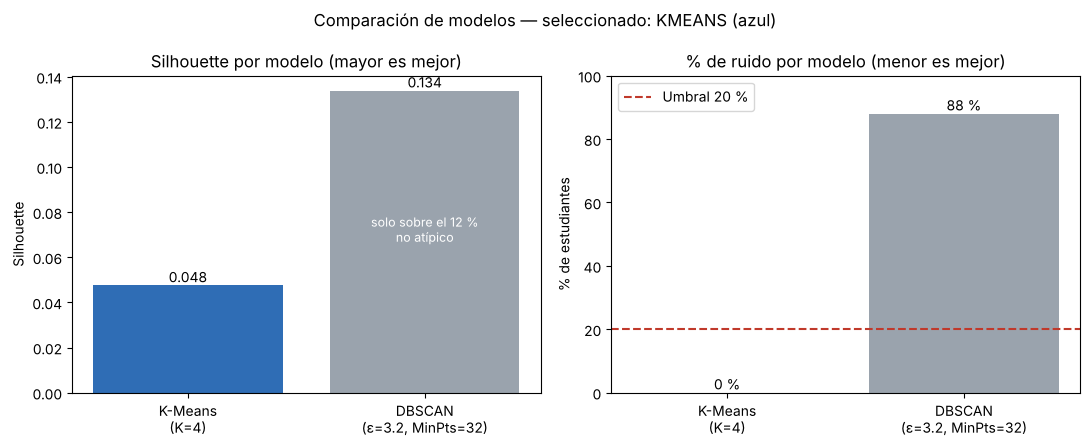

In [7]:
etiquetas = ["K-Means\n(K=4)", f"DBSCAN\n(ε={EPS}, MinPts={MIN_SAMPLES})"]
colores = ["#2f6db5" if s == "si" else "#9aa3ad" for s in comparacion["seleccionado"]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

barras = axes[0].bar(etiquetas, comparacion["silhouette"], color=colores)
axes[0].bar_label(barras, fmt="%.3f")
axes[0].set_title("Silhouette por modelo (mayor es mejor)")
axes[0].set_ylabel("Silhouette")
axes[0].text(1, comparacion.loc[1, "silhouette"] / 2, "solo sobre el 12 %\nno atípico",
             ha="center", color="white", fontsize=9)

ruido_pct = comparacion["noise_pct"] * 100
barras = axes[1].bar(etiquetas, ruido_pct, color=colores)
axes[1].bar_label(barras, fmt="%.0f %%")
axes[1].axhline(UMBRAL_RUIDO * 100, color="#c0392b", linestyle="--", label="Umbral 20 %")
axes[1].set_title("% de ruido por modelo (menor es mejor)")
axes[1].set_ylabel("% de estudiantes")
axes[1].set_ylim(0, 100)
axes[1].legend(loc="upper left")

fig.suptitle(f"Comparación de modelos — seleccionado: {modelo_final.upper()} (azul)")
fig.tight_layout()
Path("figs").mkdir(exist_ok=True)
fig.savefig("figs/comparacion.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación y Argumento para Defensa:**
1. *¿Qué significa?* A la izquierda DBSCAN parece ganar; a la derecha se ve el costo: su barra de ruido supera de lejos la línea del 20 %.
2. *Decisión:* los dos paneles juntos justifican elegir K-Means; ninguno de los dos basta por separado.
3. *Defensa:* "Una métrica de calidad que ignora a la mayoría de los datos no puede decidir sola; por eso comparamos calidad (Silhouette) y cobertura (ruido) lado a lado."

## 7. Interpretación de segmentos (modelo final: K-Means)

**Propósito y fundamento:** un cluster sin nombre no le sirve a la institución. Se promedian las variables **en su escala original** con `groupby().mean()` para leer cada perfil en unidades reales (horas, puntos, % de asistencia). Las proporciones de `Part_Time_Job` y `Counseling_Access` se calculan sobre los registros con dato. Los nombres vienen de `segments/segments_kmeans.json` (Paquete A); aquí se contrastan con los promedios y se les asigna una recomendación.

In [8]:
SEGMENTOS = json.loads(Path("segments/segments_kmeans.json").read_text(encoding="utf-8"))
RECOMENDACION = {
    "Rezago y presión financiera":
        "Becas o ayuda económica, tutorías para materias pendientes y plan de recuperación académica.",
    "Participación y apoyo familiar":
        "Mantener el acompañamiento; invitarlos como mentores pares de otros grupos.",
    "Baja asistencia y alta pantalla":
        "Alertas tempranas de asistencia y talleres sobre uso de pantallas y hábitos de sueño.",
    "Buen GPA con seguimiento de bienestar":
        "Reconocimiento académico y ofrecer consejería: alto estrés financiero y menor acceso a apoyo.",
}
assert set(SEGMENTOS.values()) == set(RECOMENDACION), "Cada segmento debe tener recomendación"

datos = df.assign(cluster=km_labels)
perfil = datos.groupby("cluster")[FEATURES].mean()
perfil.insert(0, "n", datos.groupby("cluster").size())
for col, nueva in [("Part_Time_Job", "prop_part_time_job"), ("Counseling_Access", "prop_counseling_access")]:
    perfil[nueva] = datos.groupby("cluster")[col].apply(lambda s: (s == "Yes").sum() / s.notna().sum())

# Debe coincidir con segments/perfiles_kmeans.csv del Paquete A.
guardado = pd.read_csv("segments/perfiles_kmeans.csv").set_index("cluster")
assert np.allclose(perfil[guardado.columns].to_numpy(dtype=float), guardado.to_numpy(dtype=float))

clave = ["n", "Previous_GPA", "Backlogs", "Attendance_Percent", "Screen_Time_Hours",
         "Financial_Stress_Score", "Stress_Level", "Family_Support_Score",
         "Motivation_Score", "prop_counseling_access"]
tabla = perfil[clave].round(2)
tabla.insert(0, "segmento", [SEGMENTOS[str(k)] for k in tabla.index])
display(tabla)

for k in perfil.index:
    nombre = SEGMENTOS[str(k)]
    print(f"Cluster {k} — {nombre} ({perfil.loc[k, 'n']} estudiantes): {RECOMENDACION[nombre]}")

,segmento,n,Previous_GPA,Backlogs,Attendance_Percent,Screen_Time_Hours,Financial_Stress_Score,Stress_Level,Family_Support_Score,Motivation_Score,prop_counseling_access
cluster,,,,,,,,,,,
0,Rezago y presión financiera,171,6.64,1.79,85.31,4.13,5.65,6.09,5.91,4.45,0.34
1,Participación y apoyo familiar,220,6.54,0.52,84.64,5.10,4.42,4.97,7.33,6.06,0.31
2,Baja asistencia y alta pantalla,206,6.60,0.73,69.09,6.72,4.27,5.31,5.18,5.38,0.37
3,Buen GPA con seguimiento de bienestar,203,7.64,0.44,69.21,5.56,5.93,5.87,7.14,5.80,0.31


Cluster 0 — Rezago y presión financiera (171 estudiantes): Becas o ayuda económica, tutorías para materias pendientes y plan de recuperación académica.
Cluster 1 — Participación y apoyo familiar (220 estudiantes): Mantener el acompañamiento; invitarlos como mentores pares de otros grupos.
Cluster 2 — Baja asistencia y alta pantalla (206 estudiantes): Alertas tempranas de asistencia y talleres sobre uso de pantallas y hábitos de sueño.
Cluster 3 — Buen GPA con seguimiento de bienestar (203 estudiantes): Reconocimiento académico y ofrecer consejería: alto estrés financiero y menor acceso a apoyo.


**Interpretación y Argumento para Defensa:**
- **Cluster 0 — Rezago y presión financiera (171):** el mayor número de materias pendientes (`Backlogs` 1.79, frente a 0.44–0.73 en los demás) y el mayor `Stress_Level` (6.09), con estrés financiero alto (5.65). → **Ayuda económica y tutorías.**
- **Cluster 1 — Participación y apoyo familiar (220):** el mayor apoyo familiar (7.33), la mayor motivación (6.06) y la mayor actividad social (5.98), con pocas materias pendientes (0.52). → **Mantener y usar como mentores.**
- **Cluster 2 — Baja asistencia y alta pantalla (206):** el mayor tiempo de pantalla (6.72 h) y asistencia baja (69.1 %, casi igual que el cluster 3, 69.2 %), con el menor apoyo familiar (5.18). → **Alertas de asistencia y hábitos.**
- **Cluster 3 — Buen GPA con seguimiento de bienestar (203):** el mejor GPA (7.64, un punto sobre el cluster 0), pero el mayor estrés financiero (5.93) y el menor acceso a consejería (30.5 %). → **Reconocimiento y consejería preventiva.**

1. *¿Qué significa para el negocio?* Cada perfil tiene una acción distinta, que es lo que exige el criterio de utilidad.
2. *¿Qué decisión técnica se toma?* Se conservan los nombres del Paquete A. Las diferencias entre grupos son de 0.5 a 2 puntos en escalas de 1 a 10, coherentes con un Silhouette bajo: son **tendencias**, no categorías tajantes.
3. *¿Cómo defenderlo? — "¿Cómo pusieron los nombres?"* Con los promedios en escala original de `groupby().mean()`: cada nombre se apoya en las variables donde el grupo es el más alto o el más bajo de los cuatro.

## 8. Exportación, verificación y prueba de inferencia

**Propósito y fundamento:** un modelo sólo sirve si la aplicación puede usarlo con datos crudos. Se verifica que (1) existen todos los artefactos del contrato que usan la app y el informe; (2) el pipeline de K-Means asigna un segmento a un registro con las 16 variables **sin escalar**, sin entrenar nada; y (3) el paquete DBSCAN, con el algoritmo `asignar_cluster_dbscan` del documento maestro, devuelve −1 cuando un registro no alcanza densidad.

In [9]:
REQUERIDOS = [
    "models/imputer.joblib", "models/scaler.joblib", "models/pca.joblib",
    "models/pipeline_kmeans.joblib", "models/pipeline_dbscan.joblib",
    "data/pca_2d.csv", "data/pca_varianza.csv",
    "segments/perfiles_kmeans.csv", "segments/labels_kmeans.csv", "segments/segments_kmeans.json",
    "segments/perfiles_dbscan.csv", "segments/labels_dbscan.csv", "segments/segments_dbscan.json",
    "tables/metrics_kmeans.csv", "tables/metrics_dbscan.csv", "tables/comparacion.csv",
    "figs/codo_kmeans.png", "figs/silhouette_kmeans.png", "figs/pca_kmeans.png",
    "figs/kdist_dbscan.png", "figs/pca_dbscan.png", "figs/comparacion.png",
]
faltan = [r for r in REQUERIDOS if not Path(r).exists()]
assert not faltan, f"Faltan artefactos: {faltan}"
print(f"Artefactos del contrato verificados: {len(REQUERIDOS)} de {len(REQUERIDOS)}")

# Inferencia con el pipeline exportado (el mismo que carga la app).
pipeline_final = joblib.load("models/pipeline_kmeans.joblib")
muestra = X_raw.iloc[[0, 1, 2]]          # tres registros reales, en escala original
pred = pipeline_final.predict(muestra)
assert np.array_equal(pred, km_labels[:3])
for i, k in zip(muestra.index, pred):
    print(f"Registro {i}: cluster {k} — {SEGMENTOS[str(k)]}")

# Inferencia DBSCAN para registros nuevos (algoritmo del documento maestro).
paquete_db = joblib.load("models/pipeline_dbscan.joblib")

def asignar_cluster_dbscan(X_new_raw, paquete):
    pasos = paquete["pipeline"].named_steps
    X_new = pasos["scaler"].transform(pasos["imputer"].transform(X_new_raw))
    dist, idx = paquete["nn_model"].kneighbors(X_new)
    return [int(paquete["core_labels"][i[0]]) if d[0] <= paquete["eps"] else -1
            for d, i in zip(dist, idx)]

print("\nDBSCAN sobre los mismos tres registros:", asignar_cluster_dbscan(muestra, paquete_db))

Artefactos del contrato verificados: 22 de 22
Registro 0: cluster 1 — Participación y apoyo familiar
Registro 1: cluster 2 — Baja asistencia y alta pantalla
Registro 2: cluster 3 — Buen GPA con seguimiento de bienestar

DBSCAN sobre los mismos tres registros: [-1, -1, 1]


**Interpretación y Argumento para Defensa:**
1. *¿Qué significa?* Todos los artefactos existen y el pipeline exportado predice lo mismo que el modelo reproducido. La app puede recibir datos crudos del formulario y llamar a `predict` sin escalar a mano.
2. *¿Qué decisión técnica se toma?* La app usa `models/pipeline_kmeans.joblib` para asignar el segmento, y `models/pca.joblib` **sólo** para dibujar el nuevo estudiante en el mapa 2D. Con DBSCAN, los mismos registros caen como −1 o en un grupo según su distancia al core más cercano, lo que confirma en la práctica el problema de cobertura.
3. *¿Cómo defenderlo? — "¿Por qué DBSCAN necesita NearestNeighbors y K-Means no?"* `KMeans` tiene `predict`: asigna el centroide más cercano. `DBSCAN` de scikit-learn no tiene `predict`; para un registro nuevo se busca el punto core más cercano y, si está a distancia ≤ ε, se hereda su etiqueta; si no, es ruido.

## 9. Resumen para la sustentación (todo el equipo)

| Pregunta típica | Respuesta corta |
| :--- | :--- |
| ¿Por qué es clustering y no clasificación? | No usamos `Burnout_Level` ni `Dropout_Risk`; los grupos salen sólo de la distancia entre estudiantes en 16 variables. |
| ¿Por qué escalar? | Ambos algoritmos usan distancia euclidiana; sin escalar, las variables con números grandes dominarían. |
| ¿Por qué K=4? | Codo de la inercia en K=4; Silhouette bajo y casi plano entre K=2 y K=9, así que se prefirió el número de perfiles más manejable. |
| ¿Por qué DBSCAN dejó 88 % de ruido? | En 16D casi ningún estudiante tiene 32 vecinos a menos de 3.2; es la maldición de la dimensionalidad. |
| ¿Por qué ganó K-Means? | Cobertura de 100 % frente a 12 %, y DBSCAN supera el umbral de ruido de 20 % fijado de antemano. |
| ¿Cuál es la principal limitación? | Silhouette de 0.047: los grupos se solapan. Son tendencias para priorizar apoyo, no diagnósticos individuales. |
| ¿Qué muestra el mapa 2D? | Sólo el 15 % de la varianza (PC1 + PC2); sirve para ubicar al estudiante, no para decidir su grupo. |